# HW2: Linear Regression

Welcome to the coding part of Homework 2. In this notebook, you will implement linear regression on California Housing dataset.

# Due Date: Sunday, May 3, at 11:59 PM

This assignment is due on **Sunday, May 3, at 11:59 PM**. You must submit your work to LearnHub by this deadline.

Goals: Practical understanding of linear regression: closed-form solution, normal equations, invertibility, pseudoinverse, SVD, regularization, different residuals...

**Instructions**:

1. Carefully read each question and its requirements.
2. Complete all TODOs in the notebook. You may add extra lines of code if needed to implement your solution.
3. For manual questions, provide clear and concise written responses.
4. Test your code thoroughly to ensure it meets the requirements.

Good luck!

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets

# Dataset
In this homework, you will use the California Housing dataset. You can download and check the details of the dataset by running the next five cells.



In [2]:
from sklearn.datasets import fetch_california_housing

california = fetch_california_housing(as_frame=True)

X = california.data
y = california.target
feature_names = list(X.columns)
target_name = california.target_names[0]

print("California dataset loaded successfully.")

California dataset loaded successfully.


In [3]:
print(california.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [4]:
#Split the data into train and test subsets.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Shape of X_train:', X_train.shape)
print('Shape of X_test:', X_test.shape)
print('Shape of y_train:', y_train.shape)
print('Shape of y_test:', y_test.shape)

Shape of X_train: (16512, 8)
Shape of X_test: (4128, 8)
Shape of y_train: (16512,)
Shape of y_test: (4128,)


In [5]:
X_train.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
14196,3.2596,33.0,5.017657,1.006421,2300.0,3.691814,32.71,-117.03
8267,3.8125,49.0,4.473545,1.041005,1314.0,1.738095,33.77,-118.16
17445,4.1563,4.0,5.645833,0.985119,915.0,2.723214,34.66,-120.48
14265,1.9425,36.0,4.002817,1.033803,1418.0,3.994366,32.69,-117.11
2271,3.5542,43.0,6.268421,1.134211,874.0,2.300000,36.78,-119.80


In [6]:
y_train.head()

,MedHouseVal
14196,1.030
8267,3.821
17445,1.726
14265,0.934
2271,0.965


# Part I: Preprocessing (5 pts)
In this part, we will analyze the data statistics in the training set and then apply normalization. You do not need to do any coding in this part.

In [7]:
#Now, we check the train set statistics.
X_train.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000
mean,3.880754,28.608285,5.435235,1.096685,1426.453004,3.096961,35.643149,-119.582290
std,1.904294,12.602499,2.387375,0.433215,1137.056380,11.578744,2.136665,2.005654
min,0.499900,1.000000,0.888889,0.333333,3.000000,0.692308,32.550000,-124.350000
25%,2.566700,18.000000,4.452055,1.006508,789.000000,2.428799,33.930000,-121.810000
50%,3.545800,29.000000,5.235874,1.049286,1167.000000,2.817240,34.260000,-118.510000
75%,4.773175,37.000000,6.061037,1.100348,1726.000000,3.280000,37.720000,-118.010000
max,15.000100,52.000000,141.909091,25.636364,35682.000000,1243.333333,41.950000,-114.310000


# **Question #1 (5 pts)**:
When you look at the mean values for each feature, what do you observe? Why do we need to apply normalization as a preprocessing?

# **Answer #1**:
By examining the mean values, it is observed that the features exist on significantly different scales; for instance, the mean for Population is approximately 1,426.45, whereas the mean for AveBedrms is only 1.10. We need to apply normalization as a preprocessing step because linear regression models are sensitive to the magnitude of input features. Without scaling, features with larger numerical ranges like Population would disproportionately dominate the cost function during training, leading to biased results. Normalization ensures that each feature contributes equally to the model's prediction and helps optimization algorithms converge more efficiently.


In [8]:
#We normalize the data using StandardScaler.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Part II: Linear regression with least-squares objective (27 pts)
Remember that we are trying to minimize the least-squares objective to obtain a linear model that will best explain the relation between the data and the target variable.

In this part, you are going to implement the closed-form solution for the least-squares objective and evaluate the obtained linear model on the test set.

In [9]:
#TODO (5 pts): Implement the closed form solution. This function should return the optimal weights. You should use np.linalg.inv().
def closed_form_least_squares(data, target):
  X_transpose = data.T
  w = np.linalg.inv(X_transpose @ data) @ X_transpose @ target
  return w

#we add a column of 1s to obtain the design matrix
n, p = X_train_scaled.shape
X_train_design = np.hstack([np.ones((n, 1)), X_train_scaled])
X_test_design = np.hstack([np.ones((len(y_test), 1)), X_test_scaled])

w = closed_form_least_squares(X_train_design, y_train)

In [13]:
#TODO (3 pts): Implement the predict(X, w) function which should return the predictions of the linear model with parameters w on X.
def predict(X, w):
  return X @ w

#TODO (5 pts): Implement the visualization function which should output a scatter plot. You should use matplotlib library.
#The x-axis should be the actual values, the y-axis should be the predicted values.
#Additionally, plot the x=y line which corresponds to the perfect prediction.
def visualize(pred, gt):
  plt.figure(figsize=(8, 6))
  plt.scatter(gt, pred, alpha=0.3, color='darkorange', label='Data Points')
  line_coords = [min(min(gt), min(pred)), max(max(gt), max(pred))]
  plt.plot(line_coords, line_coords, color='darkred', linestyle='--', linewidth=2, label='Perfect Prediction (x=y)')

  plt.xlabel('Actual Values')
  plt.ylabel('Predicted Values')
  plt.title('Actual vs. Predicted Housing Values')
  plt.legend()
  plt.grid(True, linestyle=':', alpha=0.6)
  plt.show()

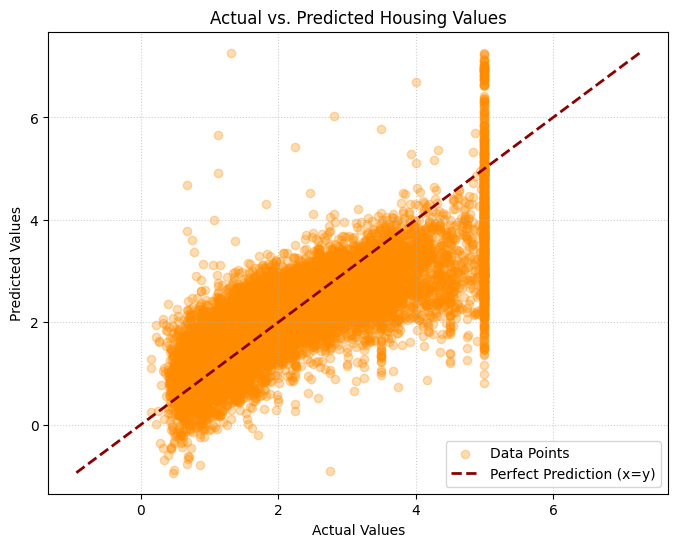

In [14]:
#predictions on train set
y_train_pred = predict(X_train_design, w)
visualize(y_train_pred, y_train)

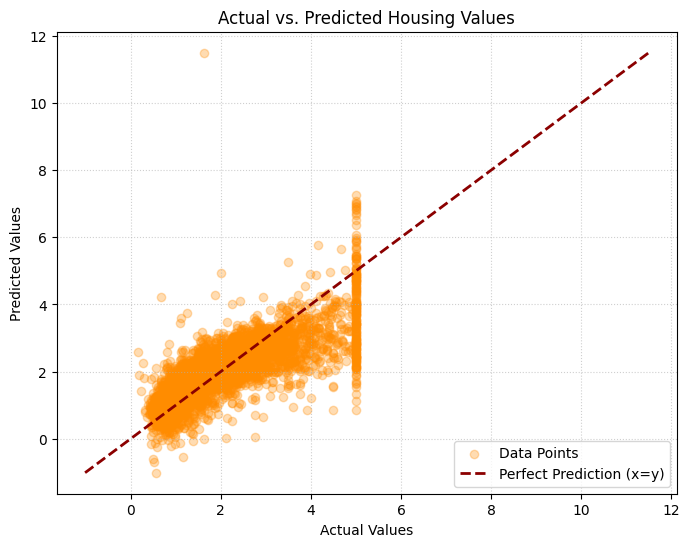

In [15]:
#predictions on test set
y_test_pred = predict(X_test_design, w)
visualize(y_test_pred, y_test)

Now you will implement 3 evaluation metrics and evaluate your linear model both on the training and test set. You should obtain the following results on the test set:

*   **MSE**: 0.56
*   **MAE**: 0.53
*   **R^2**: 0.58



In [16]:
#TODO (3 pts): Implement Mean Squared Error metric manually. Do not use external libraries.
def calculate_mse(gt, pred):
  mse = np.mean((gt - pred)**2)
  return mse

#TODO (3 pts): Implement Mean Absolute Error metric manually. Do not use external libraries.
def calculate_mae(gt, pred):
  mae = np.mean(np.abs(gt - pred))
  return mae

#TODO (3 pts): Implement R^2 (R-squared) metric manually. Do not use external libraries.
def calculate_r_squared(gt, pred):
  ss_res = np.sum((gt - pred)**2)
  ss_tot = np.sum((gt - np.mean(gt))**2)

  r2 = 1 - (ss_res / ss_tot)
  return r2

mse_train = calculate_mse(y_train, y_train_pred)
mse_test = calculate_mse(y_test, y_test_pred)

mae_train = calculate_mae(y_train, y_train_pred)
mae_test = calculate_mae(y_test, y_test_pred)

r_squared_train = calculate_r_squared(y_train, y_train_pred)
r_squared_test = calculate_r_squared(y_test, y_test_pred)

print(f'MSE on train set: {mse_train:.2f}')
print(f'MSE on test set: {mse_test:.2f}')
print("----------------")
print(f'MAE on train set: {mae_train:.2f}')
print(f'MAE on test set: {mae_test:.2f}')
print("----------------")
print(f'R^2 on train set: {r_squared_train:.2f}')
print(f'R^2 on test set: {r_squared_test:.2f}')

MSE on train set: 0.52
MSE on test set: 0.56
----------------
MAE on train set: 0.53
MAE on test set: 0.53
----------------
R^2 on train set: 0.61
R^2 on test set: 0.58


# **Question #2** (5 pts):
If you are trying to improve your model, among these metrics, which one(s) would you like to be higher and which one(s) would you like to be lower? Why?

# **Answer #2**:
To improve the model, we would like MSE and MAE to be lower, while R square should be higher. MSE and MAE represent the average error of our predictions; therefore, minimizing these values indicates that our model's predictions are becoming more accurate and closer to the actual ground truth values. On the other hand, R square measures the proportion of variance in the target variable explained by the model, so a higher R square value closer to 1.0 signifies a better overall fit and higher explanatory power.

# Part III: Normal Equation Gets Tricky: SVD, Pseudoinverse and Ridge (43 pts)
Remember that the data matrix in a linear regression problem may be ill-conditioned, meaning that we may not be able to derive the closed-form solution.

In this part, we will simulate this problem by adding a synthetic feature to the data matrix and then try to come up with a solution.

In [17]:
#Here, we are creating a new feature which is obtained by multiplying the 'HouseAge' column with 0.5.
idx_houseage = feature_names.index('HouseAge')
train_feat_dup = 0.5 * X_train_scaled[:, idx_houseage:idx_houseage+1]
test_feat_dup = 0.5 * X_test_scaled[:, idx_houseage:idx_houseage+1]

#Now, we are adding this new feature to the data matrix.
X_train_bad = X_train_scaled.copy()
X_test_bad = X_test_scaled.copy()
X_train_bad = np.hstack([X_train_bad, train_feat_dup])
X_test_bad = np.hstack([X_test_bad, test_feat_dup])

X_train_design_bad = np.hstack([np.ones((n,1)), X_train_bad])
X_test_design_bad = np.hstack([np.ones((len(y_test),1)), X_test_bad])

try:
  w_bad = closed_form_least_squares(X_train_design_bad, y_train)
  print(w_bad)
except Exception as e:
  print("Exception occurred: ", e)

Exception occurred:  Singular matrix


# **Question #3** (5 pts):
When you ran the cell above, what was the output? What does it mean? Why did this happen?

# **Answer #3**:
The output was "Exception occurred: Singular matrix". This indicates that the matrix (X(Transpose)X) is non-invertible, which prevents the calculation of the closed-form solution. This occurred because a new feature was added as a direct linear combination of an existing one (specifically, 0.5x 'HouseAge'), leading to perfect multicollinearity. In linear algebra, when columns are linearly dependent, the resulting matrix is singular (has a determinant of zero), making it mathematically impossible to compute the inverse required for the normal equation.

Now, we will compute SVDs of the design matrices we have and use their pseudoinverses to obtain optimal parameters of our linear model.

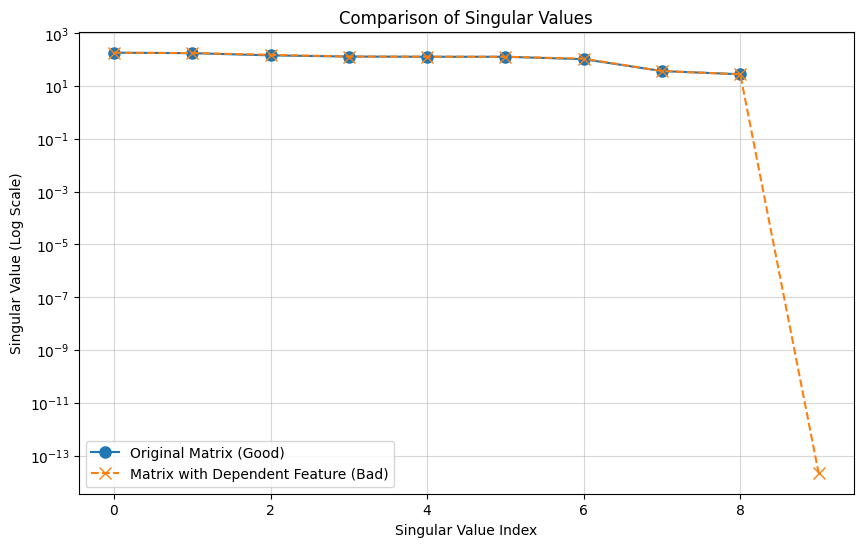

In [18]:
#TODO (8 pts): Compute SVDs for both X_train_design and X_train_design_bad and visualize the singular values for both.
#The singular values should be plotted in log scale. You can use np.linalg.svd().
_, s_good, _ = np.linalg.svd(X_train_design)
_, s_bad, _ = np.linalg.svd(X_train_design_bad)
plt.figure(figsize=(10, 6))

plt.plot(s_good, 'o-', label='Original Matrix (Good)', markersize=8)
plt.plot(s_bad, 'x--', label='Matrix with Dependent Feature (Bad)', markersize=8)

plt.yscale('log')
plt.xlabel('Singular Value Index')
plt.ylabel('Singular Value (Log Scale)')
plt.title('Comparison of Singular Values')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()

# **Question #4** (5 pts):
What does SVD or singular values of a matrix correspond to? Comment on the singular values of the two design matrices.

# **Answer #4**:
Singular Value Decomposition decomposes a matrix into its core components, where singular values represent the magnitude or "strength" of information along each principal dimension of the data. Geometrically, they correspond to the lengths of the semi-axes of the hyper-ellipsoid defined by the matrix transformation.

Regarding the two design matrices:

Original Matrix (Good): All singular values remain relatively large and stable, indicating that the features are linearly independent and the matrix is full rank (well-conditioned).

Matrix with Dependent Feature (Bad): While most values follow the original trend, the final singular value drops drastically to nearly zero. This indicates that one dimension is redundant due to perfect multicollinearity, confirming that the matrix is singular and mathematically non-invertible.

In [19]:
#TODO (5 pts): Implement this function which should return the closed-form solution using the pseudo-inverse. You can use np.linalg.pinv().
def pseudoinverse_soln(data, target):
  w = np.linalg.pinv(data) @ target
  return w

#closed-form solution with the original data
w_pinv = pseudoinverse_soln(X_train_design, y_train)

y_train_pred_pinv = predict(X_train_design, w_pinv)
y_test_pred_pinv = predict(X_test_design, w_pinv)

mse_train_pinv = calculate_mse(y_train_pred, y_train)
mse_test_pinv = calculate_mse(y_test_pred, y_test)

#closed-form solution with the new feature
w_pinv_bad = pseudoinverse_soln(X_train_design_bad, y_train)

y_train_pred_bad = predict(X_train_design_bad, w_pinv_bad)
y_test_pred_bad = predict(X_test_design_bad, w_pinv_bad)

mse_train_bad = calculate_mse(y_train_pred_bad, y_train)
mse_test_bad = calculate_mse(y_test_pred_bad, y_test)

#you should observe that we get the same results with the pseudo-inverse solution compared to the results we got in part II.
print(f'MSE on train set (pinv): {mse_train_pinv:.2f}')
print(f'MSE on test set (pinv): {mse_test_pinv:.2f}')
print("----------------")
print(f'MSE on train set (bad): {mse_train_bad:.2f}')
print(f'MSE on test set (bad): {mse_test_bad:.2f}')

MSE on train set (pinv): 0.52
MSE on test set (pinv): 0.56
----------------
MSE on train set (bad): 0.52
MSE on test set (bad): 0.56


Another way to deal with ill-conditioned matrices is Ridge trick. Now, you will implement the closed-form solution for Ridge regression.

Lambda: 0.1 -> Test MSE: 0.5559
Lambda: 1 -> Test MSE: 0.5559
Lambda: 10 -> Test MSE: 0.5555


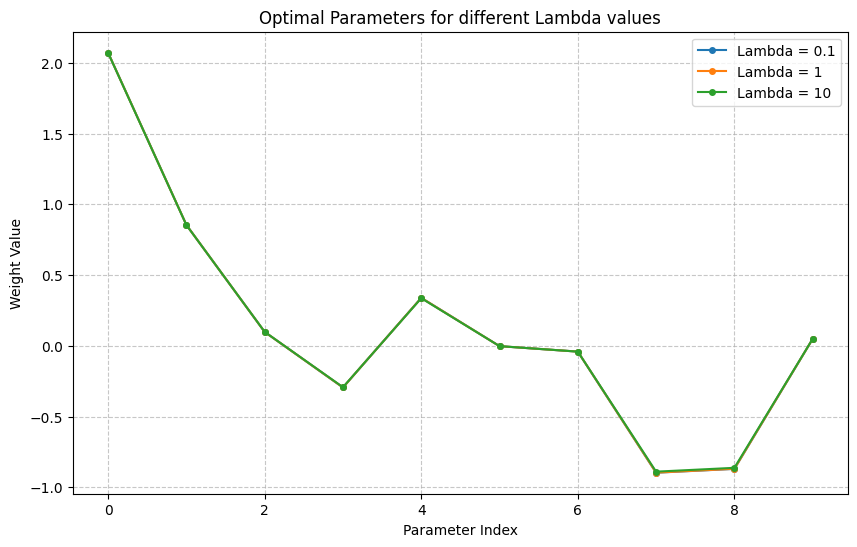

In [20]:
#TODO (5 pts): Implement this function which should return the closed-form solution for w with Ridge regression. You can use np.linalg.inv().
def ridge_closed_form(data, target, lambda_reg):
  n_features = data.shape[1]
  I = np.identity(n_features)
  X_transpose = data.T
  inside_inv = (X_transpose @ data) + (lambda_reg * I)
  w = np.linalg.inv(inside_inv) @ X_transpose @ target
  return w

#TODO (5 pts): Compute the optimal parameters separately with the given values for lambda.
#Visualize the resulting parameters with each lambda on a single plot.
#Output the MSE on the test set for each resulting model.
lambdas = [0.1, 1, 10]
plt.figure(figsize=(10, 6))

for l in lambdas:
    w_ridge = ridge_closed_form(X_train_design_bad, y_train, l)
    y_test_pred = predict(X_test_design_bad, w_ridge)
    mse_test = calculate_mse(y_test, y_test_pred)

    print(f"Lambda: {l} -> Test MSE: {mse_test:.4f}")
    plt.plot(w_ridge, label=f'Lambda = {l}', marker='o', markersize=4)

plt.title('Optimal Parameters for different Lambda values')
plt.xlabel('Parameter Index')
plt.ylabel('Weight Value')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# **Question #5** (10 pts):
a) How does Ridge regularization solve the invertibility problem?

b) How do the parameters of the linear model change when you increase lambda? How would you find the optimal lambda?

# **Answer #5**:
a) Ridge regularization solves the invertibility problem by adding a positive penalty term λ to the diagonal of the (X(Transpose)X) matrix, resulting in (X(Transpose)X+λI). This mathematical adjustment ensures that the eigenvalues of the matrix are strictly positive, making the matrix non-singular and thus invertible, even when perfect multicollinearity exists in the original data.

b) As lambda increases, the magnitude of the linear model parameters shrinks toward zero, which penalizes large weights and simplifies the model to prevent overfitting. To find the optimal lambda, a common approach is to use Cross-Validation. By training the model with various lambda values and measuring performance on a validation set, the lambda that minimizes the validation error is selected as the optimal choice.

# Part IV: Error Function (25 pts)
So far, we mostly worked on linear regression with the least-squares objective. However, we can introduce other error functions that will behave differently, i.e. find different solutions for the dataset we have.

In the last part, you will be introduced to Huber regression and analyze the differences between Least-Squares and Huber regression. Specifically, we will augment the data we have to observe the behavioral changes in a better and clearer way.

You will use scikit-learn library in this part. You can check the details of Huber regression from this link: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.HuberRegressor.html.

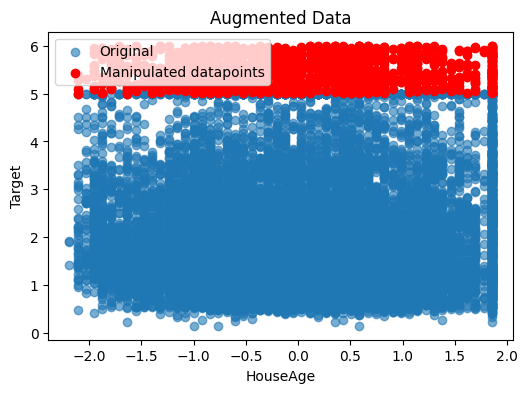

In [21]:
#Here, we randomly select 1200 datapoints and augment their target variable.
np.random.seed(42)
X_aug = X_train_scaled.copy()
y_aug = y_train.copy().to_numpy()
aug_idx = np.random.choice(len(y_aug), size=1200, replace=False)
y_aug[aug_idx] = 5.0 + np.random.rand(len(aug_idx))

#Now, we visualize the augmented dataset. We plot 'HouseAge' feature vs target for easier visualization.
plt.figure(figsize=(6,4))
plt.scatter(X_train_scaled[:, idx_houseage], y_train, label='Original', alpha=0.6)
plt.scatter(X_train_scaled[aug_idx, idx_houseage], y_aug[aug_idx], color='red', label='Manipulated datapoints')
plt.xlabel('HouseAge'); plt.ylabel('Target'); plt.legend(); plt.title('Augmented Data')
plt.show()

# **Question #6** (5 pts):
In the augmented dataset, red points represent extreme values that do not follow the original trend. What type of data augmentation was applied to generate these points (i.e., what do these new data points represent)?

# **Answer #6**:
The red points represent outliers or synthetic noise intentionally injected into the dataset. This type of data augmentation is performed by assigning extreme values to the target variable regardless of the input feature ('HouseAge'), effectively creating high-leverage points that do not follow the original data trend. These points represent anomalies or faulty data entries used to evaluate the robustness of the linear regression model and to demonstrate how sensitive standard least-squares objectives can be to extreme deviations.

In [22]:
from sklearn.linear_model import HuberRegressor

#First, we compute the optimal parameters for least squares objective on both the original and augmented data.
X_design_aug = np.hstack([np.ones((n,1)), X_aug])

w_least_squares = pseudoinverse_soln(X_train_design, y_train)
w_least_squares_aug = pseudoinverse_soln(X_design_aug, y_aug)

#Now, obtain the predictions of the models obtained by least squares objective on the test set.
y_least_squares_test = X_test_design @ w_least_squares
y_least_squares_aug_test = X_test_design @ w_least_squares_aug

print(f"Least-squares: original vs. augmented: {calculate_mse(y_test, y_least_squares_test):.2f}, {calculate_mse(y_test, y_least_squares_aug_test):.2f}")

#TODO (10 pts): compute the optimal parameters for Huber objective on both the original and augmented data.
#You should check the link above to learn about the functions/attributes of HuberRegressor.
#Then, obtain the predictions of the models obtained by HuberRegressor on the test set.
#Finally, print the MSE for both models.
huber_orig = HuberRegressor()
huber_orig.fit(X_train_scaled, y_train)

huber_aug = HuberRegressor()
huber_aug.fit(X_aug, y_aug)

y_huber_test = huber_orig.predict(X_test_scaled)
y_huber_aug_test = huber_aug.predict(X_test_scaled)

mse_huber_orig = calculate_mse(y_test, y_huber_test)
mse_huber_aug = calculate_mse(y_test, y_huber_aug_test)

print(f"Huber: original vs. augmented: {mse_huber_orig:.2f}, {mse_huber_aug:.2f}")

Least-squares: original vs. augmented: 0.56, 0.61
Huber: original vs. augmented: 0.58, 0.57


# **Question #7** (10 pts):
a) How do the results differ between models trained on the original dataset versus the augmented dataset when using Least Squares and when using the Huber loss?

b) You should observe that Huber loss is more robust to the augmentation performed. Why? You should check the formulation of the Huber loss and explain how it remains robust to this type of datapoints.

# **Answer #7**:
a) When using Least Squares, the test MSE increases noticeably from 0.56 on the original dataset to 0.61 on the augmented dataset. This demonstrates that Least Squares is sensitive to the extreme outliers added during augmentation, as the squared error term in its objective function heavily penalizes large residuals and pulls the regression line toward the outliers. In contrast, the Huber loss results remain extremely stable, with the MSE barely changing (0.58 vs 0.57), showing that the model is significantly less affected by the augmented data points.

b) Huber loss is more robust because it employs a hybrid approach to handling residuals. For small errors, it behaves like a quadratic function (similar to MSE), allowing for efficient optimization near the minimum. However, for residuals larger than a specific threshold (ϵ), it switches to a linear function (similar to MAE). By penalizing large outliers linearly rather than quadratically, Huber loss prevents extreme data points from dominating the gradients during training, allowing the model to focus on the primary trend of the data rather than the noise.